## **How many people are in the room?** 
We want to answer it with sensor data only

1. We load the data and look at it
2. We check the quality of the data , if it has any missing values or duplicates
3. We look at the target: how many people are in the room, and how often
4. We split the data into three parts (train, validation, test), in time order
5. We define the decision (how much to ventilate) and its costs
6. We compute two simple baselines, every model later must do better than them


## **IMPORTS**

In [3]:
import numpy as np                      
import pandas as pd                    
import matplotlib.pyplot as plt        
from sklearn.metrics import accuracy_score,f1_score   

# colors and plot style
BLUE, ORANGE, INK, GREY = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,   
                     "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110})

# 1 - Loading the data

In [6]:
df = pd.read_csv("Occupancy_Estimation.csv")   

print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])
df.head(300)    

Number of rows: 10129
Number of columns: 19


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,2017/12/22,13:49:25,26.06,27.06,26.00,26.38,164,254,276,70,0.30,0.26,0.64,0.08,910,1.661538,1,1,3
296,2017/12/22,13:49:55,26.06,27.00,26.00,26.31,165,254,275,70,0.83,0.27,0.62,0.14,910,1.553846,1,1,3
297,2017/12/22,13:50:26,26.06,27.00,26.00,26.31,164,254,274,70,1.20,0.28,0.22,0.11,910,1.446154,1,1,3
298,2017/12/22,13:50:56,26.13,27.06,26.00,26.31,165,254,274,71,1.13,1.40,1.51,1.36,910,1.392308,1,1,3


**What we see:** 10129 rows and 19 columns

- `Date`and`Time`: when the measure was taken
- 16 sensor columns:
  - From `S1_Temp` to `S4_Temp`: temperature, in celsius
  - From `S1_Light` to `S4_Light`: light, in lux
  - From `S1_Sound` to `S4_Sound`: sound, in volts
  - From `S5_CO2`: CO2 in the air, in ppm (parts per million)
  - From `S5_CO2_Slope`: how fast CO2 goes up or down
  - From `S6_PIR`, `S7_PIR`: motion detectors (1 = movement detected, 0 = no mvmt)
- `Room_Occupancy_Count`: **the target**, the number of people, from 0 to 3. It was written down by hand

In [7]:
# We put date and time together into only one real timestamp, so we can sort and cut the data by time
df["ts"] =pd.to_datetime(df["Date"]+" "+df["Time"])

# Check: are the rows already in time order?
print("Rows are in time order:", df["ts"].is_monotonic_increasing)

TARGET = "Room_Occupancy_Count" #name of the target column                           
features =[c for c in df.columns if c.startswith("S")]     # the 16 sensor columns
print(len(features),"sensor variables:",features)

Rows are in time order: True
16 sensor variables: ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']


# 2: Check the quality of the data

Before we use the data, we check two common problems: missing values & duplicates

In [8]:
print("Missing values in the whole table :",int(df.isna().sum().sum()))   # count empty cells
print("Duplicated rows :",int(df.duplicated().sum()))                      # count repeated rows

Missing values in the whole table : 0
Duplicated rows : 0


Result:there are no missing values and no duplicates. So we do not need to fill in or remove anything

### Summary of the 16 sensor variables
For each sensor we show its unit, its mean, its standard deviation (how much it varies), its minimum and its maximum

In [10]:
units = ["°C"] * 4 + ["lux"] * 4 + ["V"] * 4 + ["ppm", "ppm per step", "0/1", "0/1"]
summary = df[features].describe().T[["mean", "std", "min", "max"]].round(2)   # .T turns the table so each sensor is a row
summary.insert(0, "unit", units)                                                # add the unit as the first column
summary

,unit,mean,std,min,max
S1_Temp,°C,25.45,0.35,24.94,26.38
S2_Temp,°C,25.55,0.59,24.75,29.00
S3_Temp,°C,25.06,0.43,24.44,26.19
S4_Temp,°C,25.75,0.36,24.94,26.56
S1_Light,lux,25.45,51.01,0.00,165.00
S2_Light,lux,26.02,67.30,0.00,258.00
S3_Light,lux,34.25,58.40,0.00,280.00
S4_Light,lux,13.22,19.60,0.00,74.00
S1_Sound,V,0.17,0.32,0.06,3.88
S2_Sound,V,0.12,0.27,0.04,3.44


# 3: Look at the target (the number of people)

In [11]:
counts = df[TARGET].value_counts().sort_index()        # how many rows for 0,1,2, 3 people
shares = (counts / len(df) * 100).round(1)             # same in percent
pd.DataFrame({"rows": counts, "percent": shares})

,rows,percent
Room_Occupancy_Count,,
0,8228,81.2
1,459,4.5
2,748,7.4
3,694,6.9


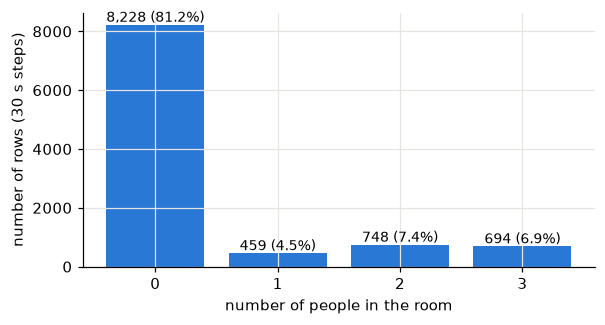

In [14]:
# Bar chart of the target
fig,ax = plt.subplots(figsize=(6, 3))
ax.bar(counts.index, counts.values, color=BLUE)
for x, n, p in zip(counts.index, counts.values, shares.values):
    ax.text(x, n + 100, f"{n:,} ({p}%)",ha="center", fontsize=9)   # writing the number above each bar
ax.set_xticks([0,1,2,3])
ax.set_xlabel("number of people in the room")
ax.set_ylabel("number of rows (30 s steps)")
plt.show()

The room is empty most of the time, it is empty 81% of the time, only about 19% of the rows have people

This is important: a  model that always answers 0 people is already right 81% of the time
So accuracy is not a good way to judge our models, we will use other measures


In [ ]:
# when were people in the room? We look at the number of rows per day and per headcount
pd.crosstab(df["Date"], df[TARGET])

Room_Occupancy_Count,0,1,2,3
Date,,,,
2017/12/22,637,205,257,363
2017/12/23,1997,254,398,130
2017/12/24,1064,0,0,0
2017/12/25,1716,0,0,0
2017/12/26,1063,0,0,0
2018/01/10,703,0,93,201
2018/01/11,1048,0,0,0


People are present only on 3 dates: 22 Dec, 23 Dec and 10 Jan
The other days are nights or holidays with an empty room

### Are some sensors redundant?
We compute the **correlation** between sensors. A correlation close to 1 means that two sensors move together,
so they give almost the same information

In [19]:
# The training rows are the ones before 23 Dec 2017, 15:00 (I explain this choice just in the part below)
train_rows =df[df["ts"]<pd.Timestamp("2017-12-23 15:00")]
corr =train_rows[features].corr()# correlation between every pair of sensors

def mean_abs_corr(cols):
    """Average absolute correlation between the sensors in `cols` (each pair counted once)"""
    c = corr.loc[cols, cols].abs().values
    return c[np.triu_indices(len(cols), 1)].mean()     # take only the pairs above the diagonal

print("Light sensors, mean|correlation|:", round(mean_abs_corr(features[4:8]), 2))
print("Temperature sensors, mean|correlation|:", round(mean_abs_corr(features[0:4]), 2))

Light sensors, mean|correlation|: 0.69
Temperature sensors, mean|correlation|: 0.85


The 4 light sensors and the 4 temperature sensors are strongly correlated. So some sensors are probably not needed
This is why we will compute **variable selection** afterwards.

# 4: Split the data in time order

We need three groups of rows:
- **train**: to fit (=learn) the models;
- **validation**: to choose between models and settings;
- **test**: to check the final model **only once**, at the end

**Why not a random split?** Two rows 30 seconds apart are almost the same. With a random split, a row in the test setwould have its "twin" in the training set. The model would look very good, but only because it has already seen almost the same moment. So we cut the data **by time**:

| Part | Period | Why |
|---|---|---|
| train | 22 Dec 10:49 → 23 Dec 15:00 | first day and a half, all headcounts 0–3 |
| validation | 23 Dec 15:00 → 24 Dec | rest of the December weekend, all headcounts 0–3 |
| test | 25 Dec → 11 Jan | Christmas (empty) + a new session two weeks later: like real use |

The first cut (23 Dec, 15:00) is in a lunch break when the room is empty, so we do not cut a session in two

In [20]:
CUT1 =pd.Timestamp("2017-12-23 15:00")   # end of train and start of validation
CUT2 =pd.Timestamp("2017-12-25 00:00")   # end of validation and start of test

#give each row a label: "train", "val" or "test"
df["split"] = np.where(df["ts"]<CUT1, "train",
                       np.where(df["ts"]< CUT2, "val","test"))

# X = the 16 sensor values (inputs),y = the number of people (target),for each part
Xtr, ytr = df.loc[df.split == "train",features],df.loc[df.split =="train", TARGET].to_numpy()
Xva, yva = df.loc[df.split == "val",features],df.loc[df.split =="val", TARGET].to_numpy()
Xte, yte = df.loc[df.split == "test",features], df.loc[df.split =="test", TARGET].to_numpy()

#number of rows per part and per headcount iin a table
split_table = pd.crosstab(df["split"], df[TARGET]).reindex(["train", "val", "test"])
split_table["total"] = split_table.sum(axis=1)
split_table

Room_Occupancy_Count,0,1,2,3,total
split,,,,,
train,2103,321,413,363,3200
val,1595,138,242,130,2105
test,4530,0,93,201,4824


I'll talk about the limitations of the test split in the report. (no row for for exactly 1 person)

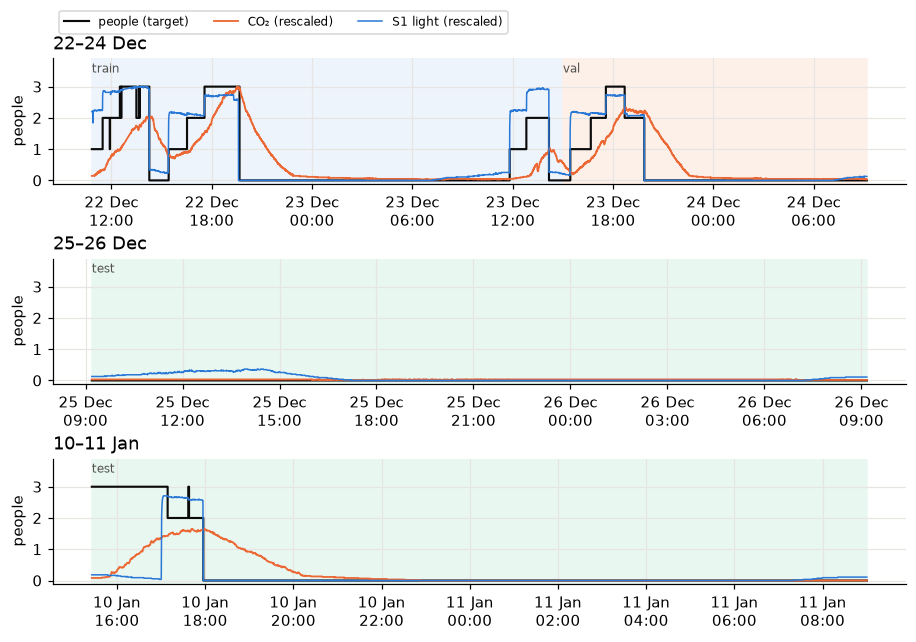

In [24]:
# Plot: the number of people over time, with the three parts in colour
# We draw one panel per recording block, because there is a gap of two weeks in the data
fig, axes = plt.subplots(3, 1, figsize=(10, 6.2), gridspec_kw={"hspace": 0.6})
blocks = [("22–24 Dec", df.ts<pd.Timestamp("2017-12-24 12:00")),
          ("25–26 Dec", (df.ts>=pd.Timestamp("2017-12-25")) & (df.ts < pd.Timestamp("2017-12-27"))),
          ("10–11 Jan", df.ts>=pd.Timestamp("2018-01-01"))]
for ax, (name, rows) in zip(axes, blocks):
    d = df[rows]
    for part, colour in (("train", "#eef4fc"),("val", "#fdf0e9"),("test", "#e9f7f1")):
        dp = d[d.split == part]
        if len(dp):  # colour the background of each part
            ax.axvspan(dp.ts.min(), dp.ts.max(), color=colour, zorder=0)
            ax.text(dp.ts.min(), 3.45, part, color=GREY, fontsize=8)
    ax.step(d.ts, d[TARGET], where="post", color=INK, lw=1.4, label="people (target)")
    # two sensors, rescaled to the 0–3 axis so we can compare their shape with the target
    ax.plot(d.ts, 3 * (d.S5_CO2 - df.S5_CO2.min()) / (df.S5_CO2.max() - df.S5_CO2.min()), color=ORANGE, lw=1.2, label="CO₂ (rescaled)")
    ax.plot(d.ts, 3 * d.S1_Light/df.S1_Light.max(), color=BLUE, lw=1.0, label="S1 light (rescaled)")
    ax.set_ylim(-0.1, 3.9); ax.set_yticks([0, 1, 2, 3]); ax.set_ylabel("people")
    ax.set_title(name, loc="left")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b\n%H:%M"))
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.15), ncol=3, fontsize=8)
plt.show()

**Other preprocessing choices:**
- We do not use Date and Time as inputs, they describe the schedule of this experiment, not the room
  A real system must work on any day
- We do not fill missing values (there are none) and we do not re-balance the classes
  We deal with the imbalance through the metric and the costs 

# 5: The decision and its costs

Knowing the number of people is useful because it helps a **decision**: how much fresh air to send into the room

- **Action** **a** = ventilation level,from 0 to 3. Level **a** gives enough air for **a** people.
- If we ventilate **too much**, we waste energy: each level costs **1**.
- If we ventilate **too little**, people breathe bad air (more CO₂): each person without enough air costs **4**.

So the cost (also called "loss") of choosing level **a** when there are really **y** people is:

$$L(a, y) = 1 \times a + 4 \times \max(y - a,\ 0)$$

The numbers 1 and 4 are **our assumption**: we say that missing air for one person is 4 times worse than
one level of energy

In [26]:
CLASSES = np.array([0, 1, 2, 3])     # possible headcounts, and also possible ventilation levels
C_E, C_U = 1.0, 4.0                  # C_E = energy cost per level, C_U = cost per person without enough air

def loss_matrix(c_e=C_E, c_u=C_U):
    """Table of costs: one row per action a (from 0 to 3), one column per true headcount y (0 to 3)."""
    a, y = np.meshgrid(CLASSES, CLASSES, indexing="ij")   # all pairs (a, y)
    return c_e * a + c_u * np.maximum(y - a, 0)

LOSS = loss_matrix()
pd.DataFrame(LOSS, index=[f"action a={a}" for a in CLASSES], columns=[f"person y={y}" for y in CLASSES])

,person y=0,person y=1,person y=2,person y=3
action a=0,0.0,4.0,8.0,12.0
action a=1,1.0,1.0,5.0,9.0
action a=2,2.0,2.0,2.0,6.0
action a=3,3.0,3.0,3.0,3.0


The decision y=a is always the best choice

### Bayes action

### From probabilities to an action (the "Bayes action")

A model does not know the true number of people. It gives a **probability** for each count

For each possible action, we compute the **expected cost** (the average cost, weighted by the probabilities),
and we choose the action with the **lowest expected cost**

With our costs, this gives a simple rule: **ventilate for at least k people as soon as
P(k people or more) ≥ 1/4 = 0.25**. Why 1/4? Going one level up always costs 1, and saves 4 only if there are
really more people. So it is worth it when that probability is at least 1/4

In [28]:
def bayes_action(P, L=LOSS):
    """For each row of probabilities P, return the action with the lowest expected cost"""
    expected_cost = P @ L.T                 # expected cost of each action,for each row
    return np.argmin(expected_cost, axis=1) # index of the cheapest action (if equal, the lower level wins)

# small ex with 3 rows of probabilities for 0, 1, 2, 3 people
P_example = np.array([[0.70, 0.10, 0.10, 0.10], # P(1 or more) = 0.30 >= 0.25 -> level 1
                      [0.80, 0.10, 0.05, 0.05],  # P(1 or more) = 0.20 < 0.25 ->level 0
                      [0.10, 0.20, 0.30, 0.40]])   # P(3) = 0.40 >= 0.25 -> level 3
print("Chosen ventilation levels:", bayes_action(P_example))   # expected:[1 0 3]

Chosen ventilation levels: [1 0 3]


The result `[1 0 3]` matches the rule. Note the first row: the most likely answer is 0 people with 70% prob,
but the rule still ventilates a little, because forgetting a person is expensive.
This is the difference between **predicting** and **deciding**

# 6: How we measure performance

We use these measures in the whole project:

- **Mean cost**: the average of L(a, y) over all rows
- **Regret** = mean cost − cost with perfect information. "Perfect information" means we always know the true
  headcount and choose a = y, regret 0 is perfect. We use regret because the three parts (train, validation, test)
  do not have the same number of people, so their raw costs cannot be compared directly
- **Macro-F1**: the F1 score for each headcount, then the average of the four, each headcount counts the same,
  even the rare ones. This is better than accuracy here
- **Accuracy**: share of correct predictions, we show it only for reference

In [29]:
def mean_cost(actions, y, L=LOSS):
    """Average cost of the chosen actions, given the true nb of people y"""
    return float(L[actions, y].mean())

def oracle_cost(y, L=LOSS):
    """cost if we always knew the truth (action = true nb of people), no policy can do better"""
    return float(L[y, y].mean())

def scores(y, predicted_count, actions):
    """summary"""
    return {"accuracy": accuracy_score(y, predicted_count),
            "macro_F1": f1_score(y, predicted_count, average="macro", zero_division=0),
            "mean_cost": mean_cost(actions, y),
            "regret": mean_cost(actions, y) - oracle_cost(y)}


for name, y in (("train", ytr), ("validation", yva), ("test", yte)):
    print(f"Perfect-information cost on {name}: {oracle_cost(y):.3f}")

Perfect-information cost on train: 0.699
Perfect-information cost on validation: 0.481
Perfect-information cost on test: 0.164


# 7: The baselines

A baseline is a very simple policy with no learning. A real model is only useful if it beats it. We use two:

1. **Never ventilate** (always predict 0 people). This is also the "majority class" classifier, because 0 is the most common answer. It saves all the energy, but it forgets every person
2. **Always ventilate for 3 people.** Nobody ever lacks air, but we waste energy all the time

We measure them on the **validation** part£

In [30]:
never = np.zeros_like(yva)        # action 0 for every row
always3 =np.full_like(yva, 3)    # action 3 for every row

baselines =pd.DataFrame({
    "Never ventilate (always predict 0)": scores(yva, never, never),
    "Always ventilate for 3": scores(yva, always3, always3),
}).T
baselines.round(3)

,accuracy,macro_F1,mean_cost,regret
Never ventilate (always predict 0),0.758,0.216,1.923,1.442
Always ventilate for 3,0.062,0.029,3.000,2.519
